In [1]:
import sys

sys.path.append("..")

import numpy as np
import os
from pathlib import Path
import json
from lib.wpt_utils import build_index_per_level
import matplotlib.pyplot as plt
from datetime import datetime
import ast
from typing import List, Tuple, Optional, Dict
from tqdm import tqdm
import sys

sys.path.append("..")
import pandas as pd
import comet_ml
import torch
import os
import pytorch_lightning as pl
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from pytorch_lightning.callbacks import EarlyStopping
from typing import Optional, Dict, Any, List
from pytorch_lightning.loggers import CometLogger
import torch.nn.functional as F
from classes.signal.signal_classes import WaveletPacket
from classes.sample.sample_classes import SampleWaveletPacket
import matplotlib.pyplot as plt
import scienceplots
from pydantic import BaseModel
# plt.style.use(["science", "ieee", "grid"])

In [2]:
import plotly.express as px

In [3]:
SEQ_1_PATH = Path("../data/wpts/sequence_1_db35")
SEQ_2_PATH = Path("../data/wpts/sequence_2_db35")
SEQ_3_PATH = Path("../data/wpts/sequence_3_db35")

In [4]:
# VALID_START_DATE_S1 = datetime(2023, 1, 16)

# VALID_START_DATE_S2 = datetime(2023, 4, 27, 11)
# VALID_END_DATE_S2 = datetime(2023, 7, 5, 11)

# VALID_START_DATE_S3 = datetime(2023, 8, 15, 15)

SEQ_1_HEALTH_END = datetime(2023, 1, 25, 10, 0, 0)
SEQ_2_HEALTH_END = datetime(2023, 5, 9, 11, 0, 0)
SEQ_3_HEALTH_END = datetime(2023, 8, 30, 11, 0, 0)

In [5]:
CABLES = ["c1", "c2", "c3", "c4"]
AXES = ["x", "y", "z"]

# Hyperparameters

# Get data

In [6]:
from lib.wpt_utils import (
    load_wavelets,
    combine_wpts,
    normalize_by_level,
)

In [7]:
data_seq_1 = load_wavelets(SEQ_1_PATH)  # , valid_start=VALID_START_DATE_S1)
data_seq_2 = load_wavelets(SEQ_2_PATH)  # , valid_start=VALID_START_DATE_S1)
# data_test = load_wavelets(SEQ_3_PATH) #, valid_start=VALID_START_DATE_S1)

100%|██████████| 6212/6212 [01:59<00:00, 51.92it/s]


# Extract features

In [8]:
data_train, data_valid = data_seq_2, data_seq_1

Schema of a sample:
```
class SingleWaveletPacketSample(BaseModel):
    x: WaveletPacket
    y: WaveletPacket
    z: WaveletPacket
    tension: float
```

```
class SampleWaveletPacket(BaseModel):
    sample_id: str
    sample_c1: SingleWaveletPacketSample
    sample_c2: SingleWaveletPacketSample
    sample_c3: SingleWaveletPacketSample
    sample_c4: SingleWaveletPacketSample
```

```
class WaveletPacket(BaseModel):
    max_level: int
    family: str
    fs: float
    energy_map: List[float]
    entropy_map: List[float]
```

In [9]:
from classes.signal.signal_classes import WaveletPacket
from classes.sample.sample_classes import SingleWaveletPacketSample, SampleWaveletPacket
from lib.wpt_utils import build_index_per_level


In [10]:
class BandRange(BaseModel):
    start: float
    end: float

    @property
    def bandwidth(self) -> float:
        return self.end - self.start

    @property
    def id(self) -> str:
        return f"{self.start}-{self.end}"


def has_intersection(range_0: BandRange, range_1: BandRange) -> bool:
    if range_1.start >= range_0.end:
        return False

    if range_0.start >= range_1.end:
        return False

    if range_1.start > range_0.start and range_0.end <= range_1.end:
        return True

    if range_0.start > range_1.start and range_1.end <= range_0.end:
        return True

    if range_1.start > range_0.start and range_1.end <= range_0.end:
        return True

    if range_0.start > range_1.start and range_0.end <= range_1.end:
        return True

In [11]:
cases = [
    (BandRange(start=0, end=128), BandRange(start=8, end=24), True),
    (BandRange(start=0, end=64), BandRange(start=32, end=67), True),
    (BandRange(start=0, end=64), BandRange(start=32, end=64), True),
    (BandRange(start=25, end=26), BandRange(start=8, end=24), False),
    (BandRange(start=25, end=26), BandRange(start=26, end=27), False),
]

for b0, b1, res in cases:
    assert has_intersection(b0, b1) == res
    assert has_intersection(b1, b0) == res


In [12]:
from typing import Literal


class SpectralFeatures(BaseModel):
    sampled_at: datetime
    id: str
    tension: float
    cable: Literal["c1", "c2", "c3", "c4"]
    level: int
    energy: float
    norm_energy: float | None = None

In [13]:
def extract_features(
    sample_wpt: SampleWaveletPacket,
    f_min: float,
    f_max: float,
    fs: float,
    max_level: int,
) -> list[SpectralFeatures]:
    """Extract spectral features from wavelet packet decomposition.

    Args:
        sample_wpt (SampleWaveletPacket): Wavelet packet decomposition for a sample
        f_min (float): Minimum frequency to consider (Hz)
        f_max (float): Maximum frequency to consider (Hz)
        fs (float): Sampling frequency (Hz)
        max_level (int): Maximum decomposition level

    Returns:
        list[SpectralFeatures]: List of spectral features containing:
            - energy: Raw energy in the frequency band
            - norm_energy: Energy normalized by maximum energy in the level
            - range: Frequency range of the band
            - level: Decomposition level
            - cable: Cable identifier
    """
    sampled_at = datetime.fromisoformat(sample_wpt.sample_id)
    allowed_range = BandRange(start=f_min, end=f_max)
    index_per_level = build_index_per_level(max_level + 1)
    features = []
    for cable in CABLES:
        wpt = getattr(sample_wpt, f"sample_{cable}")
        tension = wpt.tension
        combined_wpt = combine_wpts([wpt.y, wpt.z])
        raw_energy = np.array(combined_wpt.energy_map)

        for level, indexes in index_per_level.items():
            num_indexes = len(indexes)
            bw = (fs / 2) / num_indexes
            freq_ranges = [
                BandRange(start=k * bw, end=(k + 1) * bw) for k in range(num_indexes)
            ]
            level_energy = raw_energy[indexes]

            # select relevant subbands
            level_features = []
            max_level_energy = 0
            for band_range, raw in zip(freq_ranges, level_energy):
                if has_intersection(band_range, allowed_range):
                    if raw > max_level_energy:
                        max_level_energy = raw
                    feat = SpectralFeatures(
                        energy=raw,
                        id=band_range.id,
                        level=level,
                        cable=cable,
                        sampled_at=sampled_at,
                        tension=tension,
                    )
                    level_features.append(feat)

            # discard levels with only one subband
            if len(level_features) == 1:
                continue

            # normalize by level
            for f in level_features:
                f.norm_energy = f.energy / bw
            features += level_features
    return features

In [14]:
f_min = 12
f_max = 18
fs = 256
max_level = 8

train_features = []
for data in data_train:
    train_features += extract_features(
        data, f_min=f_min, f_max=f_max, fs=fs, max_level=max_level
    )

valid_features = []
for data in data_valid:
    valid_features += extract_features(
        data, f_min=f_min, f_max=f_max, fs=fs, max_level=max_level
    )

In [15]:
df_train = pd.DataFrame([f.model_dump() for f in train_features])
df_valid = pd.DataFrame([f.model_dump() for f in valid_features])

In [16]:
def engineer_feature(x: np.ndarray, db: bool = False) -> np.ndarray:
    f = []
    for xx in x:
        outer = np.divide.outer(xx, xx)
        if db:
            outer = 20 * np.log10(outer)
        f.append(outer[np.triu_indices(len(outer))].ravel())
    return np.array(f)

In [17]:
df_train["key"] = (
    df_train["cable"].astype(str) + "_" + df_train["sampled_at"].astype(str)
)
df_valid["key"] = (
    df_valid["cable"].astype(str) + "_" + df_valid["sampled_at"].astype(str)
)

In [18]:
class Meta(BaseModel):
    key: str
    cable: str
    sampled_at: datetime
    tension: float


In [19]:
train_meta = {
    row.key: Meta(
        key=row.key, cable=row.cable, sampled_at=row.sampled_at, tension=row.tension
    )
    for row in df_train.itertuples(index=False)
}

In [20]:
valid_meta = {
    row.key: Meta(
        key=row.key, cable=row.cable, sampled_at=row.sampled_at, tension=row.tension
    )
    for row in df_valid.itertuples(index=False)
}

In [21]:
features_train = df_train.pivot(index=["key"], columns="id", values="norm_energy")
features_valid = df_valid.pivot(index=["key"], columns="id", values="norm_energy")

In [23]:
features_train.to_numpy().shape

(24848, 22)

In [22]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Fit
pca = Pipeline([("scale", StandardScaler()), ("pca", PCA(2))])
x_numpy = engineer_feature(features_train.to_numpy(), db=True)
pca.fit(x_numpy)

Pipeline(steps=[('scale', StandardScaler()), ('pca', PCA(n_components=2))])

In [ ]:
class Hyperparams(BaseModel):
    n_components: int
    n_states: int
    level: int
    freq_min: float
    freq_max: float


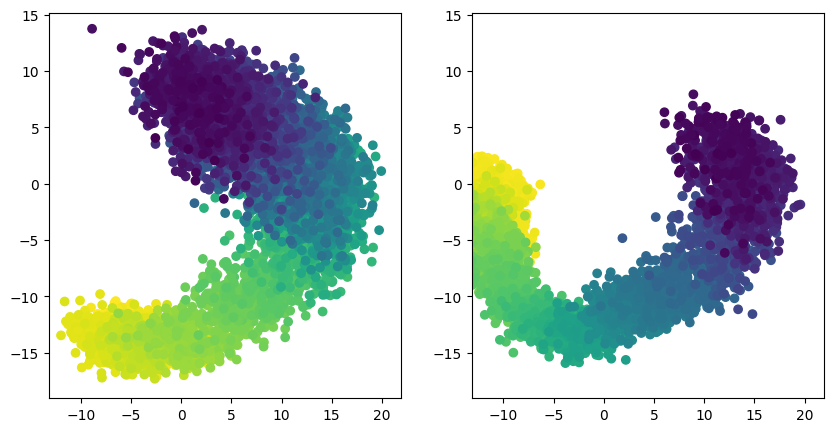

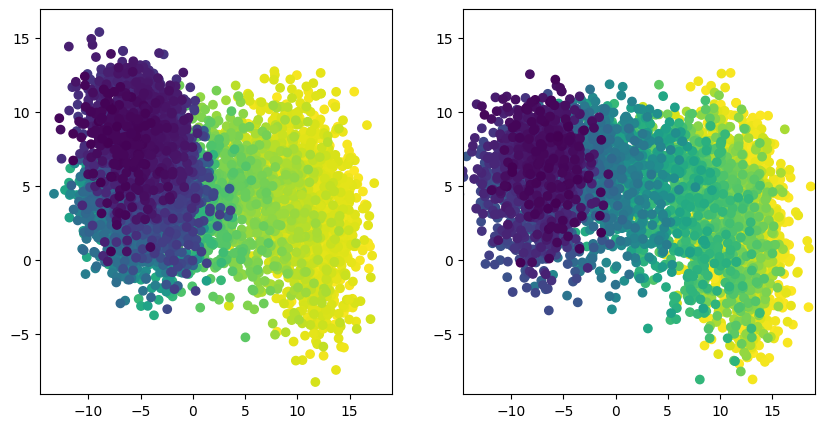

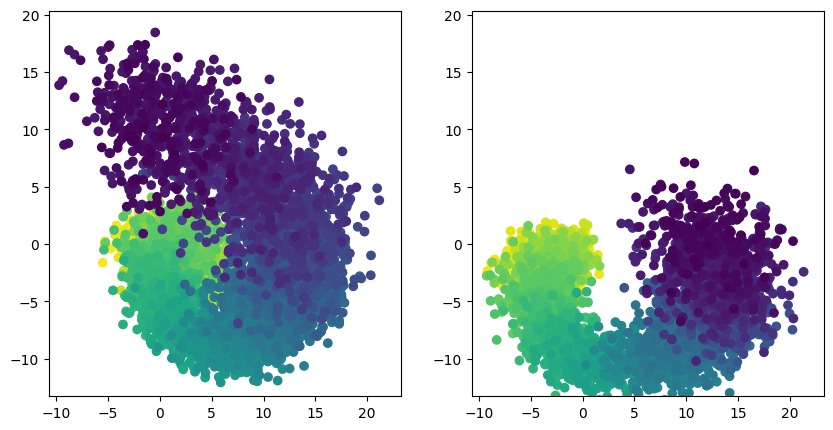

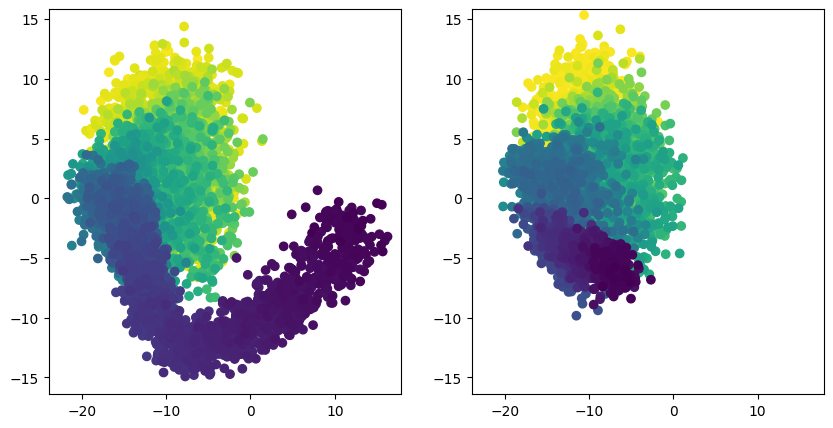

In [139]:
# Predict
y_train = {}
y_valid = {}
for cable in CABLES:
    train_cable_meta = [meta for meta in train_meta.values() if meta.cable == cable]
    train_cable_keys = [meta.key for meta in train_cable_meta]
    train_features_cable = features_train.loc[list(train_cable_keys)]
    tension_train = [meta.tension for meta in train_cable_meta]
    x_train = engineer_feature(train_features_cable.to_numpy(), db=True)
    y_train[cable] = pca.transform(x_train)

    valid_cable_meta = [meta for meta in valid_meta.values() if meta.cable == cable]
    valid_cable_keys = [meta.key for meta in valid_cable_meta]
    valid_features_cable = features_valid.loc[list(valid_cable_keys)]
    tension_valid = [meta.tension for meta in valid_cable_meta]
    x_valid = engineer_feature(valid_features_cable.to_numpy(), db=True)
    y_valid[cable] = pca.transform(x_valid)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.scatter(y_train[cable][:, 0], y_train[cable][:, 1], c=tension_train)
    x_min = y_train[cable][:, 0].min()
    x_max = y_train[cable][:, 0].max()
    y_min = y_train[cable][:, 1].min()
    y_max = y_train[cable][:, 1].max()
    plt.ylim([y_min * 1.1, y_max * 1.1])
    plt.xlim([x_min * 1.1, x_max * 1.1])

    plt.subplot(1, 2, 2)
    plt.scatter(y_valid[cable][:, 0], y_valid[cable][:, 1], c=tension_valid)
    plt.ylim([y_min * 1.1, y_max * 1.1])
    plt.xlim([x_min * 1.1, x_max * 1.1])

# HMM

In [21]:
from hmmlearn.hmm import GaussianHMM

In [22]:
lengths = [len(y) for y in y_train.values()]

In [23]:
def build_left_right_transition_matrix(num_components: int) -> np.ndarray:
    transition_matrix = np.zeros((num_components, num_components))
    for i in range(num_components):
        if i == num_components - 1:
            transition_matrix[i, i] = 1
        elif i == 0:
            transition_matrix[i, i] = 0.9
            transition_matrix[i, i + 1] = 0.1
        else:
            transition_matrix[i, i] = 0.9
            transition_matrix[i, i + 1] = 0.1
            # transition_matrix[i, i-1] = 0.1
    return transition_matrix

In [24]:
fit_sequences = [y for y in y_train.values()]
valid_sequences = [y for y in y_valid.values()]

In [25]:
# # Apply moving average filter to smooth the sequences
# window_size = 5  # Can be adjusted based on desired smoothing level
# smooth_fit_sequences = []
# smooth_valid_sequences = []

# for sequence in fit_sequences:
#     # Apply moving average to each dimension separately
#     smoothed_x = np.convolve(sequence[:,0], np.ones(window_size)/window_size, mode='valid')
#     smoothed_y = np.convolve(sequence[:,1], np.ones(window_size)/window_size, mode='valid')

#     # Recombine the smoothed dimensions
#     smoothed_sequence = np.column_stack((smoothed_x, smoothed_y))
#     smooth_fit_sequences.append(smoothed_sequence)

# # Update the sequences to use smoothed versions
# fit_sequences = smooth_fit_sequences

# # Update lengths for HMM since smoothing reduces sequence length slightly
# lengths = [len(y) for y in fit_sequences]


In [26]:
hmm = GaussianHMM(
    n_components=6, covariance_type="full", init_params="smc", params="stmc"
)
hmm.transmat_ = build_left_right_transition_matrix(hmm.n_components)
hmm.fit(np.vstack(fit_sequences), lengths=lengths);

C:\Users\eduar\AppData\Local\Temp\ipykernel_3652\902265132.py:19: UserWarning: The following kwargs were not used by contour: 'label'
  plt.contour(X, Y, Z, levels=5, colors=colors[i], alpha=0.6, label=f'State {i}')
C:\Users\eduar\AppData\Local\Temp\ipykernel_3652\902265132.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0, 0.5, 'Dimension 2')

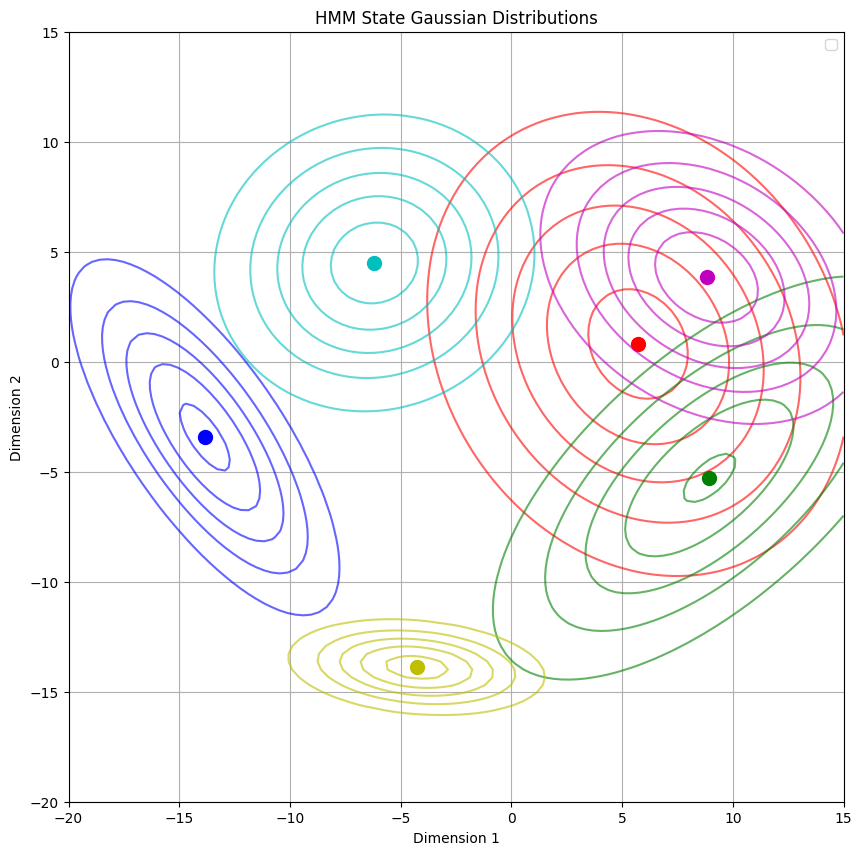

In [27]:
# Plot the learned 2D Gaussian distributions
plt.figure(figsize=(10, 10))
colors = ["r", "g", "b", "y", "c", "m"]  # One color per state
x = np.linspace(-20, 15, 100)
y = np.linspace(-20, 15, 100)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

for i in range(hmm.n_components):
    mean = hmm.means_[i]
    cov = hmm.covars_[i]

    # Calculate 2D Gaussian
    from scipy.stats import multivariate_normal

    rv = multivariate_normal(mean, cov)
    Z = rv.pdf(pos)

    # Plot contours
    plt.contour(X, Y, Z, levels=5, colors=colors[i], alpha=0.6, label=f"State {i}")
    plt.plot(mean[0], mean[1], colors[i] + "o", markersize=10)  # Plot mean

plt.grid(True)
plt.legend()
plt.title("HMM State Gaussian Distributions")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")


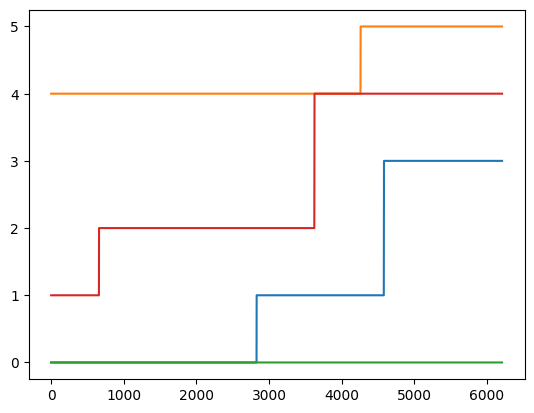

In [28]:
train_scores = []
for i, seq in enumerate(fit_sequences):
    predictions = hmm.predict(seq)
    train_scores.append(hmm.score(seq))
    plt.plot(predictions)

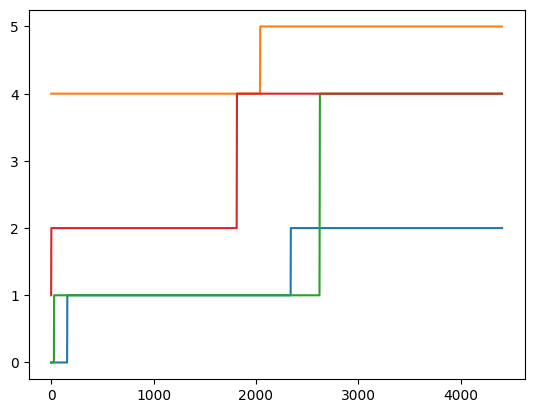

In [29]:
valid_scores = []
for i, seq in enumerate(valid_sequences):
    predictions = hmm.predict(seq)
    valid_scores.append(hmm.score(seq))
    plt.plot(predictions)

In [30]:
np.min(valid_scores)

np.float64(-28297.885096845293)

# Tests

In [169]:
class FeatureParams(BaseModel):
    f_min: float
    f_max: float
    fs: float
    max_level: int
    db: bool


class SpectralFeatures(BaseModel):
    sampled_at: datetime
    id: str
    tension: float
    cable: Literal["c1", "c2", "c3", "c4"]
    value: float
    level: int | None = None

In [170]:
class FeatureExtractor:
    def __init__(self, params: FeatureParams):
        self.params = params

    def _extract_bands(self, sample_wpt: SampleWaveletPacket) -> list[SpectralFeatures]:
        """Extract spectral features from wavelet packet decomposition.

        Args:
            sample_wpt (SampleWaveletPacket): Wavelet packet decomposition for a sample
            f_min (float): Minimum frequency to consider (Hz)
            f_max (float): Maximum frequency to consider (Hz)
            fs (float): Sampling frequency (Hz)
            max_level (int): Maximum decomposition level

        Returns:
            list[SpectralFeatures]: List of spectral features containing:
                - energy: Raw energy in the frequency band
                - norm_energy: Energy normalized by maximum energy in the level
                - range: Frequency range of the band
                - level: Decomposition level
                - cable: Cable identifier
        """
        sampled_at = datetime.fromisoformat(sample_wpt.sample_id)
        allowed_range = BandRange(start=self.params.f_min, end=self.params.f_max)
        index_per_level = build_index_per_level(self.params.max_level + 1)
        features = []
        for cable in CABLES:
            wpt = getattr(sample_wpt, f"sample_{cable}")
            tension = wpt.tension
            combined_wpt = combine_wpts([wpt.y, wpt.z])
            raw_energy = np.array(combined_wpt.energy_map)

            for level, indexes in index_per_level.items():
                num_indexes = len(indexes)
                bw = (self.params.fs / 2) / num_indexes
                freq_ranges = [
                    BandRange(start=k * bw, end=(k + 1) * bw)
                    for k in range(num_indexes)
                ]
                level_energy = raw_energy[indexes]

                # select relevant subbands
                level_features = []
                max_level_energy = 0
                for band_range, raw in zip(freq_ranges, level_energy):
                    if has_intersection(band_range, allowed_range):
                        if raw > max_level_energy:
                            max_level_energy = raw
                        feat = SpectralFeatures(
                            value=raw / bw,  # normalized energy
                            id=band_range.id,
                            level=level,
                            cable=cable,
                            sampled_at=sampled_at,
                            tension=tension,
                        )
                        level_features.append(feat)

                # discard levels with only one subband
                if len(level_features) == 1:
                    continue

                features += level_features
        return features

    def _extract_features(
        self, raw_features: list[SpectralFeatures]
    ) -> list[SpectralFeatures]:
        band_df = self._features_to_df(raw_features)
        pivoted_band_df = band_df.pivot(
            index=["cable", "sampled_at", "tension"], columns="id", values="value"
        )
        features = []
        for key, row in pivoted_band_df.iterrows():
            x = row.to_numpy()
            ratios = np.divide.outer(x, x)
            ind = np.triu_indices(len(ratios))
            triu_ratios = ratios[ind].ravel()
            if self.params.db:
                triu_ratios = 20 * np.log10(triu_ratios)
            for i, data in enumerate(triu_ratios):
                features.append(
                    SpectralFeatures(
                        sampled_at=key[1],
                        cable=key[0],
                        tension=key[2],
                        value=data,
                        id=str(i),
                    )
                )
        return features

    def _features_to_df(self, features: list[SpectralFeatures]) -> pd.DataFrame:
        df = pd.DataFrame([f.model_dump() for f in features])
        df["key"] = df["cable"].astype(str) + "_" + df["sampled_at"].astype(str)
        return df

    def transform(self, data: list[SampleWaveletPacket]) -> list[SpectralFeatures]:
        band_features: list[SpectralFeatures] = []
        for d in data:
            band_features += self._extract_bands(d)
        features = self._extract_features(band_features)
        return features

In [171]:
params = FeatureParams(f_min=10, f_max=18, fs=256, max_level=5, db=True)

extractor = FeatureExtractor(params)
features = extractor.transform(data_train)

In [208]:
class ReductionParams(BaseModel):
    n_components: int


class ReductionModel:
    def __init__(self, params: ModelParams):
        self.params = params
        self.reduction_pipeline = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=self.params.n_components)),
            ]
        )

    def fit(self, data: list[SpectralFeatures]) -> None:
        df = features_to_df(data)
        pivoted_df = df.pivot(
            index=["cable", "sampled_at", "tension"], columns="id", values="value"
        )
        x = pivoted_df.to_numpy()
        self.reduction_pipeline.fit(x)

    def transform(self, data: list[SpectralFeatures]) -> list[SpectralFeatures]:
        df = features_to_df(data)
        pivoted_df = df.pivot(
            index=["cable", "sampled_at", "tension"], columns="id", values="value"
        )
        x = pivoted_df.to_numpy()
        meta = pivoted_df.reset_index()[["cable", "sampled_at", "tension"]]
        y = self.reduction_pipeline.transform(x)
        out = []
        for record in zip(
            y,
            meta["sampled_at"].to_list(),
            meta["cable"].to_list(),
            meta["tension"].to_list(),
        ):
            for i, value in enumerate(record[0]):
                out.append(
                    SpectralFeatures(
                        sampled_at=record[1],
                        id=str(i),
                        tension=record[3],
                        value=value,
                        cable=record[2],
                    )
                )
        return out


In [209]:
model_params = ReductionParams(n_components=5)
model = ReductionModel(model_params)

In [210]:
model.fit(features)

In [201]:
reduced_features = model.transform(features)

In [202]:
class ModelCalibration(BaseModel):
    cable: Literal["c1", "c2", "c3", "c4"]
    id: str
    value: float

In [203]:
class CalibrationModel:
    def __init__(self):
        self.calibrations: list[ModelCalibration] = []

    def calibrate(
        self,
        data: list[SpectralFeatures],
        start_date: datetime | None = None,
        end_date: datetime | None = None,
    ) -> None:
        features = features_to_df(data)
        if start_date is not None:
            features = features[features["sampled_at"] >= start_date]
        if end_date is not None:
            features = features[features["sampled_at"] <= end_date]
        grouped = features.groupby(["cable", "id"])["value"].mean().reset_index()
        self.calibrations = [ModelCalibration(**row) for _, row in grouped.iterrows()]

    def transform(self, data: list[SpectralFeatures]) -> list[SpectralFeatures]:
        transformed = []
        calibration_dict = {}
        for calibration in self.calibrations:
            calibration_dict[calibration.id, calibration.cable] = calibration.value

        for feature in data:
            feature.value = feature.value - calibration_dict[feature.id, feature.cable]
            transformed.append(feature)
        return transformed

In [204]:
from datetime import timedelta

In [205]:
calibration_model = CalibrationModel()
calibration_model.calibrate(
    reduced_features,
    end_date=SEQ_2_HEALTH_END,
    start_date=SEQ_2_HEALTH_END - timedelta(days=14),
)

In [206]:
calibrated_features = calibration_model.transform(reduced_features)

In [227]:
from hmmlearn.hmm import GaussianHMM

In [257]:
class SequenceParams(BaseModel):
    n_states: int


class SequenceModel:
    def __init__(self, params: SequenceParams):
        self.params = params

    def _build_left_right_transition_matrix(self) -> np.ndarray:
        transition_matrix = np.zeros((self.params.n_states, self.params.n_states))
        for i in range(self.params.n_states):
            if i == self.params.n_states - 1:
                transition_matrix[i, i] = 1
            elif i == 0:
                transition_matrix[i, i] = 0.9
                transition_matrix[i, i + 1] = 0.1
            else:
                transition_matrix[i, i] = 0.9
                transition_matrix[i, i + 1] = 0.1
                # transition_matrix[i, i-1] = 0.1
        return transition_matrix

    def fit(self, data: list[SpectralFeatures]) -> None:
        df = features_to_df(data)
        cables = df.cable.unique()

        # Format data to hmmlearn format
        data_list: list[np.ndarray] = []
        lens: list[int] = []
        for cable in cables:
            cable_df = df.loc[df["cable"] == cable]
            cable_df = cable_df.sort_values(by="sampled_at")
            pivoted_df = cable_df.pivot(
                index=["sampled_at"], columns="id", values="value"
            )
            data_list.append(pivoted_df.to_numpy())
            lens.append(len(pivoted_df))
        data_list = np.vstack(data_list)

        # Fit model
        self.model = GaussianHMM(
            n_components=self.params.n_states,
            covariance_type="full",
            init_params="smc",
            params="stmc",
        )
        self.model.transmat_ = self._build_left_right_transition_matrix()
        self.model.fit(data_list, lens)

    def predict(
        self, data: list[SpectralFeatures]
    ) -> tuple[list[SpectralFeatures], list[float]]:
        df = features_to_df(data)
        cables = df.cable.unique()

        # Format data to hmmlearn format
        output: list[SpectralFeatures] = []
        scores = []
        for cable in cables:
            cable_df = df.loc[df["cable"] == cable]
            cable_df = cable_df.sort_values(by="sampled_at")
            pivoted_df = cable_df.pivot(
                index=["sampled_at"], columns="id", values="value"
            )
            x = pivoted_df.to_numpy()
            y = self.model.predict(x)
            for i, value in enumerate(y):
                output.append(
                    SpectralFeatures(
                        sampled_at=cable_df.iloc[i]["sampled_at"],
                        id="0",
                        cable=cable,
                        value=value,
                        tension=cable_df.iloc[i]["tension"],
                    )
                )
            s = self.model.score(x)
            scores.append(s)
        return output, scores

In [258]:
sequence_params = SequenceParams(n_states=6)
seq_model = SequenceModel(sequence_params)

In [259]:
seq_model.fit(calibrated_features)

In [260]:
pred, scores = seq_model.predict(calibrated_features)

In [261]:
pred_df = features_to_df(pred)

In [263]:
px.line(pred_df, x="sampled_at", y="value", color="cable")